# Floor-posture radar — exploring the data

A person is lying on the floor. A ceiling-mounted mmWave radar looks down at
them, and a camera next to it records what actually happened.

This notebook walks through what is in a recording, what the radar config
tells you about the limits of the sensor, and how to look at a frame. Run it
top to bottom once, then use the viewer sections to browse.

**Setup** — from the bundle root (the folder holding `data/` and `recorder/`):

```bash
python -m venv venv

venv\Scripts\activate                 # Windows cmd / PowerShell
source venv/Scripts/activate          # Windows, git-bash
source venv/bin/activate              # macOS / Linux

python -m pip install -e recorder
python -m pip install jupyter ipykernel
python -m ipykernel install --user --name floor-posture --display-name "floor-posture"
python -m jupyter lab
```

Then pick the **floor-posture** kernel in Jupyter (Kernel → Change Kernel).

That registration step is the one people skip, and it is the one that matters:
`pip install` puts the reader in your virtualenv, but `jupyter lab` may well
launch a Jupyter installed somewhere else, whose kernel is a different Python
that has never heard of it. Symptom: `ModuleNotFoundError: No module named
'vt_radar'`. Using `python -m ...` throughout keeps everything pinned to the
interpreter you just activated.

If you hit it anyway, the next cell falls back to loading the reader straight
out of `recorder/` and prints which Python it is actually running, so you are
not stuck.

In [31]:
import os
import sys
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Bundle root. Adjust if you moved the notebook out of the bundle folder.
ROOT = "../../data/raw/floor_posture_dataset/"
if not os.path.isdir(os.path.join(ROOT, "data")):
    raise SystemExit(
        f"No data/ folder under {os.path.abspath(ROOT)}.\n"
        "Set ROOT to the folder that contains data/, recorder/ and previews/."
    )

RECORDER = os.path.abspath(os.path.join(ROOT, "recorder"))


def _load_reader():
    """Import the bits of the reader this notebook uses."""
    from loguru import logger
    from vt_radar.data.dataset import TLVDataset
    from vt_radar.data.rangedoppler import RangeDoppler
    from vt_radar.config.ti_config import ConfigFile

    return logger, TLVDataset, RangeDoppler, ConfigFile


# The reader lives in recorder/. If it is not installed in the kernel running
# this notebook, fall back to the copy sitting next to us rather than making you
# fight with virtualenvs -- a common way to lose an afternoon is to pip install
# into one Python and run Jupyter from another.
try:
    logger, TLVDataset, RangeDoppler, ConfigFile = _load_reader()
except ModuleNotFoundError:
    if os.path.isdir(RECORDER) and RECORDER not in sys.path:
        sys.path.insert(0, RECORDER)
    try:
        logger, TLVDataset, RangeDoppler, ConfigFile = _load_reader()
        print(f"vt_radar was not installed in this kernel; loaded it from {RECORDER}")
    except ModuleNotFoundError as exc:
        raise SystemExit(
            f"Cannot import '{exc.name}'.\n\n"
            f"This notebook is running this interpreter:\n    {sys.executable}\n\n"
            "Install the reader and its dependencies into THAT one:\n"
            f'    "{sys.executable}" -m pip install -e "{RECORDER}"\n\n'
            "then restart the kernel (Kernel -> Restart).\n\n"
            "Copy the path exactly. The usual cause of this error is pip installing\n"
            "into one Python while Jupyter runs a different one."
        ) from exc

logger.remove()  # the loader is chatty; silence it for the notebook

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["image.cmap"] = "viridis"

print("bundle  :", os.path.abspath(ROOT))
print("python  :", sys.executable)
print("reader  :", os.path.dirname(sys.modules["vt_radar.data.dataset"].__file__))

bundle  : /Users/sigurdurhaukur/Documents/rug/ai-engineering/data/raw/floor_posture_dataset
python  : /Users/sigurdurhaukur/Documents/rug/ai-engineering/.venv/bin/python
reader  : /Users/sigurdurhaukur/Documents/rug/ai-engineering/data/raw/floor_posture_dataset/recorder/vt_radar/data


## 1. What's in the bundle

`MANIFEST.csv` has one row per recording. Every recording is a directory of
`data_*.h5` chunks (500 frames each) plus the `.cfg` the radar was running.

In [32]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"))
shapes = pd.read_csv(os.path.join(ROOT, "HEATMAP_SHAPES.csv"))
man = man.merge(shapes[["rec", "heatmap", "cfg"]], left_on="dataset", right_on="rec", how="left")

available = {os.path.basename(p) for p in glob.glob(os.path.join(ROOT, "data", "*", "*"))}
man["present"] = man.dataset.isin(available)

print(f"{man.present.sum()} of {len(man)} recordings present in this folder")
print(f"{man.loc[man.present, 'frames'].sum():,} frames, {man.loc[man.present, 'size_mb'].sum():.0f} MB")
man.loc[man.present, ["dataset", "room", "frames", "size_mb", "heatmap", "recorded", "has_labels"]]

35 of 35 recordings present in this folder
49,900 frames, 4982 MB


,dataset,room,frames,size_mb,heatmap,recorded,has_labels
0,2309__20230927_145000,room1,900,86.0,"(64, 16)",2023-09-27 12:51,False
1,2310__20231006_154117,room1,2600,245.7,"(64, 16)",2023-10-06 13:45,True
2,2310__20231006_155527,room1,1500,138.8,"(64, 16)",2023-10-06 13:57,False
3,2310__20231006_161334,room1,1500,143.8,"(64, 16)",2023-10-06 14:15,False
4,2310__20231020_143847,room1,1500,128.7,"(64, 16)",2023-10-20 12:39,False
5,2310__20231027_134002,room1,1800,176.6,"(64, 16)",2023-10-27 11:45,False
6,2310__20231027_140700,room1,1700,147.0,"(64, 16)",2023-10-27 12:12,False
7,2310__20231027_142000,room1,1500,135.9,"(64, 16)",2023-10-27 12:20,False
8,2310__20231027_143141,room1,2000,186.6,"(64, 16)",2023-10-27 12:37,False
9,2310__20231027_150820,room1,1700,156.4,"(64, 16)",2023-10-27 13:13,False


If you only have part 1 of the transfer, most rows will show `present = False`.
Everything below works on whatever you do have.

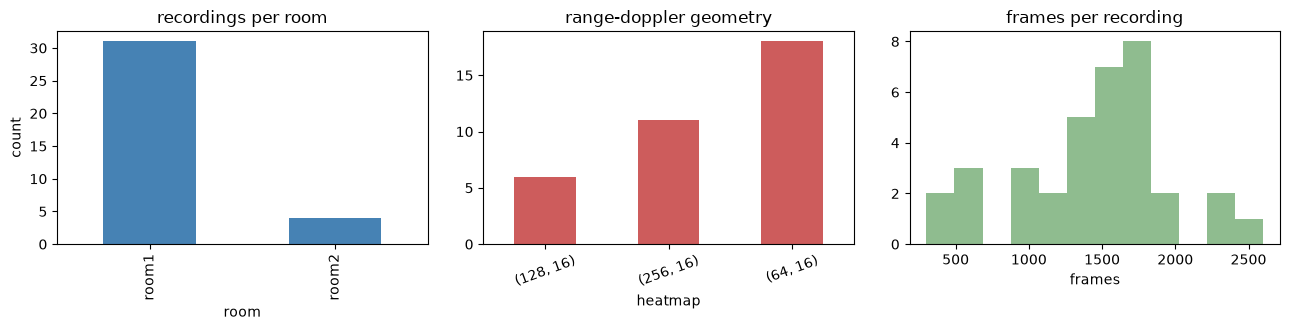

In [33]:
present = man[man.present].copy()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
present.groupby("room").size().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("recordings per room"); ax[0].set_ylabel("count")
present.groupby("heatmap").size().plot.bar(ax=ax[1], color="indianred")
ax[1].set_title("range-doppler geometry"); ax[1].tick_params(axis="x", rotation=20)
ax[2].hist(present.frames, bins=12, color="darkseagreen")
ax[2].set_title("frames per recording"); ax[2].set_xlabel("frames")
plt.tight_layout()
plt.show()

### The heatmap is not one fixed size

The doppler axis is always 16 bins, but the range axis is 64, 128 or 256
depending on the radar config. **You cannot stack recordings into one array
without handling this.** The next section shows where that number comes from.

## 2. The radar config — what the sensor can and cannot see

Each recording carries the `.cfg` that was actually sent to the radar. It fixes
the physics of what you're looking at: how finely range is resolved, how far the
radar sees, and how fast something must move to register a doppler shift.

`ConfigFile` parses it and derives the useful quantities.

In [34]:
def load_cfg(rec):
    '''Parse the .cfg that shipped with a recording.'''
    d = rec_dir(rec)
    cfgs = sorted(glob.glob(os.path.join(d, "*.cfg")))
    if not cfgs:
        raise FileNotFoundError(f"no .cfg in {d}")
    c = ConfigFile()
    c.parseCfg(cfgs[0])
    return c, os.path.basename(cfgs[0])


def rec_dir(rec):
    '''Directory for a recording name, whichever room it is in.'''
    hits = glob.glob(os.path.join(ROOT, "data", "*", rec))
    if not hits:
        raise FileNotFoundError(f"{rec} is not in this folder (another zip part?)")
    return hits[0]


def cfg_summary(rec):
    c, name = load_cfg(rec)
    s = c.sensor()
    return {
        "recording": rec,
        "cfg": name,
        "range_res_m": round(s.range_resolution, 4),
        "range_max_m": round(s.range_max, 2),
        "range_bins": s.num_range_bins,
        "doppler_bins": s.num_doppler_bins,
        "doppler_res_m_s": round(s.doppler_resolution, 4),
        "max_velocity_m_s": round(s.max_velocity, 3),
        "tx": s.num_tx_antennas,
        "rx": s.num_rx_antennas,
    }


rows = []
for rec in present.dataset:
    try:
        rows.append(cfg_summary(rec))
    except Exception as e:
        rows.append({"recording": rec, "cfg": f"<{type(e).__name__}>"})
cfgs = pd.DataFrame(rows)
cfgs

,recording,cfg,range_res_m,range_max_m,range_bins,doppler_bins,doppler_res_m_s,max_velocity_m_s,tx,rx
0,2309__20230927_145000,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
1,2310__20231006_154117,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
2,2310__20231006_155527,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
3,2310__20231006_161334,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
4,2310__20231020_143847,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
5,2310__20231027_134002,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
6,2310__20231027_140700,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
7,2310__20231027_142000,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
8,2310__20231027_143141,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
9,2310__20231027_150820,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4


Read that table as the sensor's limits:

- **`range_res_m`** — two things closer together than this merge into one range
  bin. A lying person is roughly 0.4 m deep, so at 4 cm resolution they span
  ~10 bins; at 17 cm they span two or three.
- **`range_max_m`** — beyond this the radar reports nothing.
- **`max_velocity_m_s`** — the fastest unambiguous motion. Breathing and small
  shifts sit near zero doppler, which is exactly where a still person lives.
- **`range_bins × doppler_bins`** is the heatmap shape you get for that
  recording.

The distinct configs in the bundle:

In [35]:
cols = ["cfg", "range_res_m", "range_max_m", "range_bins", "doppler_bins",
        "doppler_res_m_s", "max_velocity_m_s", "tx", "rx"]
distinct = cfgs.dropna(subset=["range_bins"]).drop_duplicates(subset=cols)[cols]
distinct.reset_index(drop=True)

,cfg,range_res_m,range_max_m,range_bins,doppler_bins,doppler_res_m_s,max_velocity_m_s,tx,rx
0,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
1,Config_4.cfg,0.0237,4.85,256,16,0.1297,1.038,3,4
2,Config_4.cfg,0.0421,4.85,256,16,0.1326,1.061,3,4
3,Thursday(02.11)_+noise.cfg,0.0468,2.40,64,16,0.2494,1.995,3,4
4,Thursday(02.11)_Exp_1.cfg,0.0468,2.40,64,16,0.2494,1.995,3,4
5,Config_3.cfg,0.0468,2.40,64,16,0.2506,2.005,3,4
6,Config_3.cfg,0.0234,2.40,128,16,0.2444,1.955,3,4
7,Config_5.cfg,0.0436,4.46,128,16,0.1206,0.965,3,4


Same scene, very different instruments. Two things in that table are worth
staring at:

**Range resolution spans roughly 0.02 m to 0.77 m — a factor of thirty.**
`Experiment_1.cfg` (the September/October recordings) uses a narrow sweep, so a
range bin is 77 cm. A person lying down is ~40 cm deep, i.e. *less than one
bin*: they are a single blob. Under `Config_4.cfg` the same person spans tens of
bins and you can see their shape. These are not interchangeable recordings.

**Maximum unambiguous velocity spans 0.2 m/s to 2.0 m/s.** `Experiment_1.cfg`
tops out at 0.199 m/s — anything faster aliases and folds back into the doppler
axis. Fine for someone lying still, misleading the moment they move.

And note the same *filename* appears twice with different numbers —
`Config_3.cfg` is 64 bins in one recording and 128 in another. **Key off the
parsed contents, never off the config's name.**

These figures describe the config that was sent to the radar. Treat them as
strong evidence rather than gospel, and sanity-check against the data: if the
geometry says the person should be at bin 30 and the energy sits at bin 3,
believe the data.

You can also dump the whole parsed config for one recording:

In [36]:
c, name = load_cfg(present.dataset.iloc[0])
print(name)
c.describe()

Experiment_1.cfg
----------------------  ------------
Profile                 #0
Start frequency         60.0 GHz
Frequency Slope         38.11 MHz/us
ADC sampling frequency  12.5 Ms/s
Samples per chirp       64.0
Idle Time               2070.0 us
ADC Valid Start Time    7.0
Ramp End Time           13.12 us
TX Start Time           1.0
----------------------  ------------
THUS: ADC Sampling Time 5.12
THUS: Sweep bandwidth 195.1232

-------------  --
NumberOfLoops  16
-------------  --
--------------------  -----
Sub-frame Index       -1
Processing Direction  Range
Minimum Value         0.0
Maximum Value         39.35
--------------------  -----
--------------------  -------
Sub-frame Index       -1
Processing Direction  Doppler
Minimum Value         -0.2
Maximum Value         0.2
--------------------  -------
----------------------------  -
detectedObjects               0
logMagRange                   0
noiseProfile                  0
rangeAzimuthElevationHeatMap  0
rangeDopplerHeatMap 

## 3. Opening a recording

`TLVDataset` takes a directory, finds the `.cfg` beside the data, and yields
`Frame` objects.

In [37]:
REC = present.dataset.iloc[0]          # change this to explore another recording
ds = TLVDataset(rec_dir(REC))
frames = list(ds)
print(f"{REC}: {len(frames)} frames")

f = frames[len(frames) // 2]
print("timestamp     :", f.timestamp)
print("heatmap       :", np.asarray(f.output.range_doppler_heatmap).shape)
print("point cloud   :", np.asarray(f.output.pointcloud).shape, "(x, y, z, doppler, snr, noise, track)")
print("camera image  :", np.asarray(f.image).shape)
print("tracks        :", f.output.num_detected_tracks)

2309__20230927_145000: 900 frames
timestamp     : 2023-09-27 12:51:54.468304
heatmap       : (64, 16)
point cloud   : (1, 7) (x, y, z, doppler, snr, noise, track)
camera image  : (480, 640, 3)
tracks        : 0


Note `tracks = 0`. The radar's built-in tracker is designed for people walking
around; a motionless person on the floor never triggers it. That is the core
difficulty of this dataset, and the reason the heatmap matters more than the
point cloud here.

## 4. Frame viewer

Camera on the left (what happened), range-doppler heatmap in the middle (what
the radar saw), point cloud on the right.

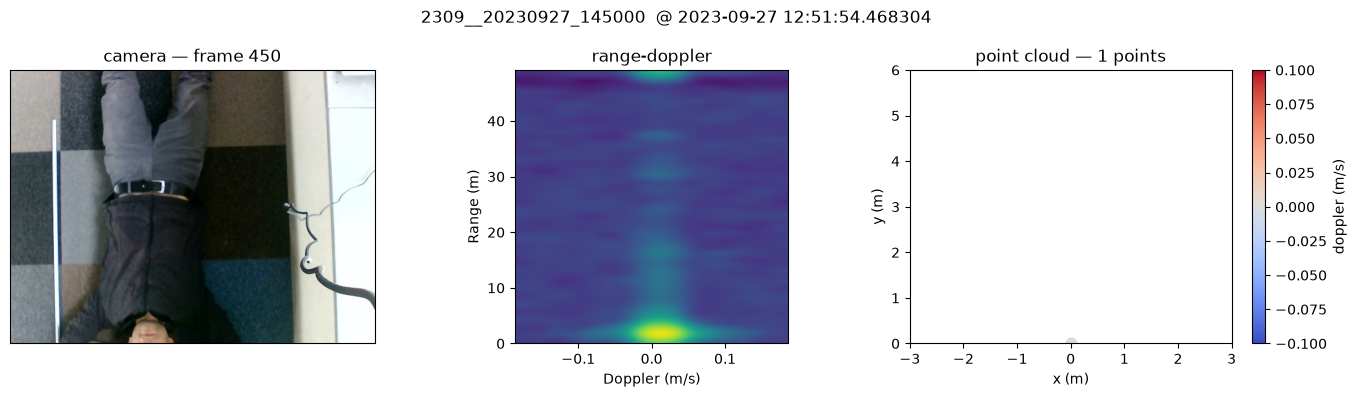

In [38]:
def show_frame(frames, i, sensor=None, title=None):
    '''Camera, range-doppler heatmap and point cloud for one frame.'''
    f = frames[i]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))

    img = np.asarray(f.image)
    if img.size:
        ax[0].imshow(img)
    else:
        ax[0].text(0.5, 0.5, "no image", ha="center")
    ax[0].set_xticks([]); ax[0].set_yticks([])
    ax[0].set_title(f"camera — frame {i}")

    heat = f.output.range_doppler_heatmap
    if sensor is not None:
        RangeDoppler(heat, sensor)._plot_heatmap(ax[1], plot_colorbar=False)
    else:
        ax[1].imshow(np.asarray(heat), aspect="auto")
    ax[1].set_title("range-doppler")

    pc = np.asarray(f.output.pointcloud, dtype=float)
    if pc.ndim == 2 and len(pc):
        sc = ax[2].scatter(pc[:, 0], pc[:, 1], c=pc[:, 3], s=60, cmap="coolwarm")
        plt.colorbar(sc, ax=ax[2], label="doppler (m/s)")
    ax[2].set_xlim(-3, 3); ax[2].set_ylim(0, 6)
    ax[2].set_xlabel("x (m)"); ax[2].set_ylabel("y (m)")
    ax[2].set_title(f"point cloud — {0 if pc.ndim < 2 else len(pc)} points")

    fig.suptitle(title or f"{REC}  @ {f.timestamp}")
    plt.tight_layout()
    return fig


sensor = ds.config.sensor() if ds.config else None
show_frame(frames, len(frames) // 2, sensor);

Step through the recording to see how little changes while someone lies still:

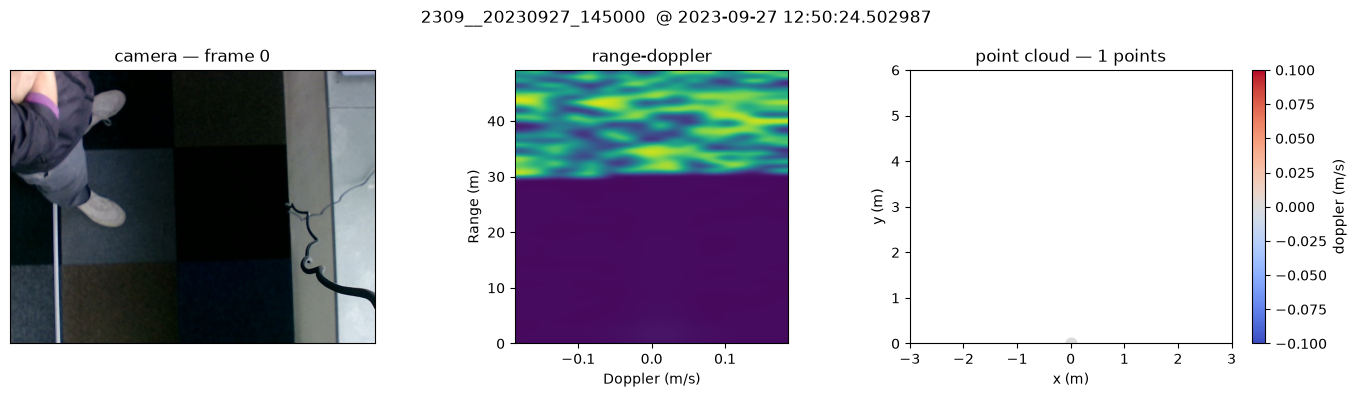

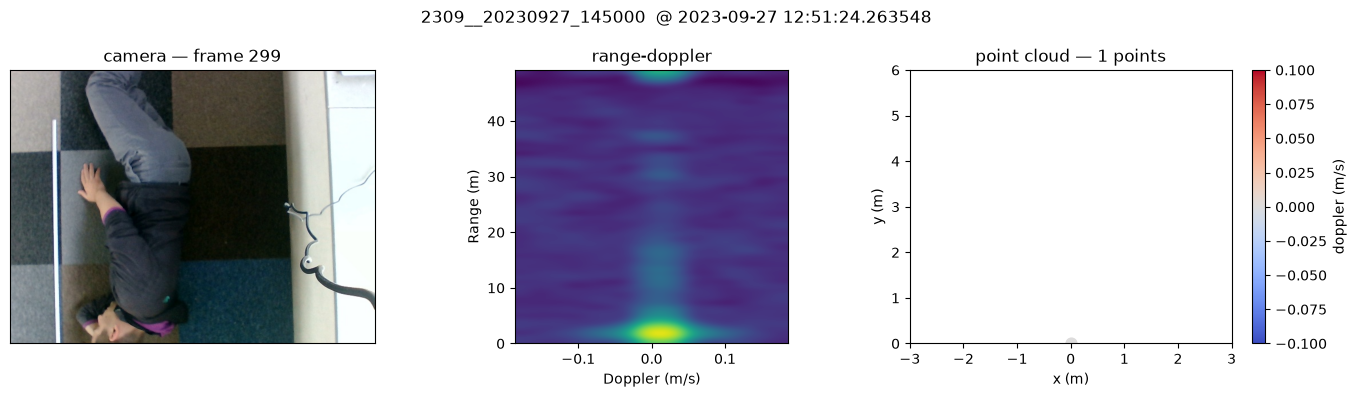

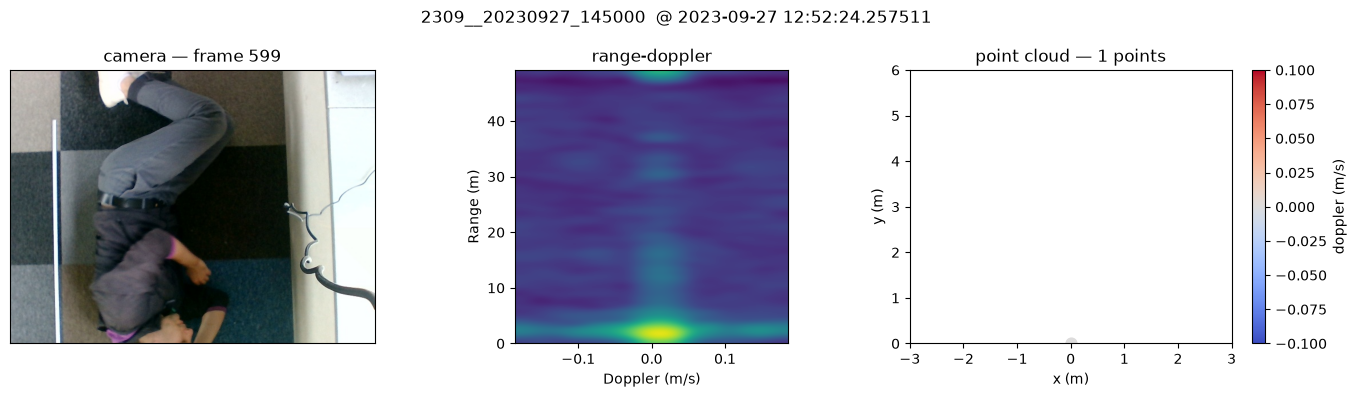

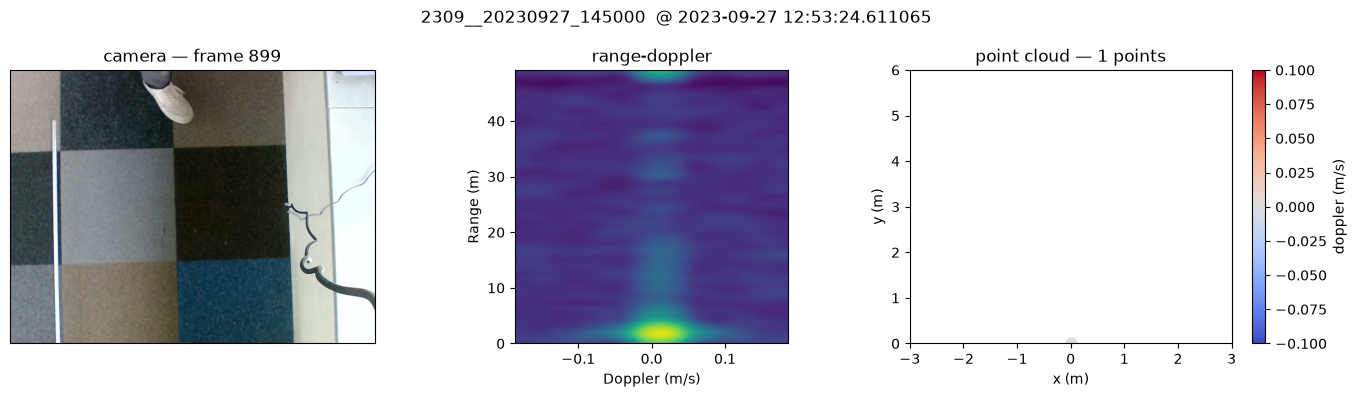

In [39]:
for i in np.linspace(0, len(frames) - 1, 4).astype(int):
    show_frame(frames, int(i), sensor)

## 5. The whole recording at a glance

One frame tells you little. Stacking every frame's range profile over time shows
the structure: a still body is a horizontal band, and movement smears across it.

range-time image: (900, 64) (frames x range bins)


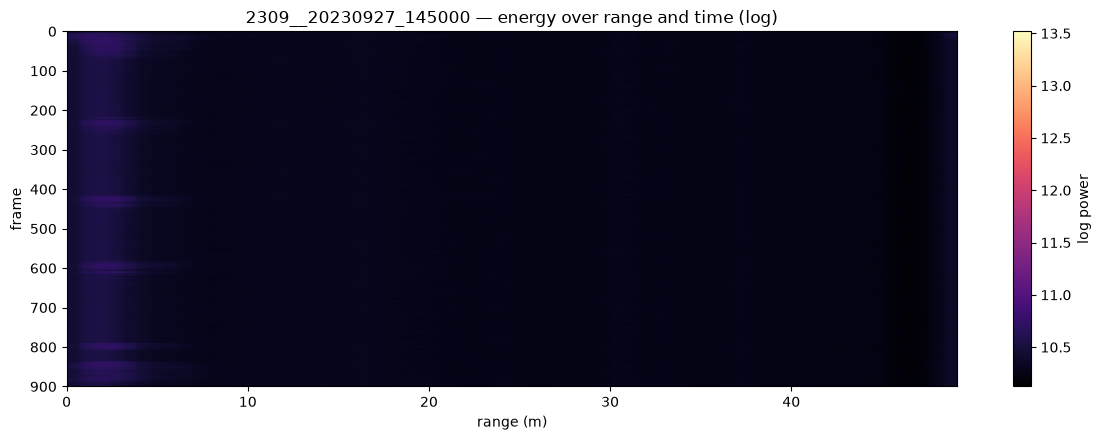

In [40]:
def range_time(frames, sensor=None, doppler="sum"):
    '''(frames x range) image: how energy at each range evolves over time.'''
    H = []
    for f in frames:
        h = np.asarray(f.output.range_doppler_heatmap, dtype=float)
        if h.ndim != 2:
            continue
        H.append(h.sum(axis=1) if doppler == "sum" else h[:, 0])
    return np.asarray(H)


rt = range_time(frames, sensor)
print("range-time image:", rt.shape, "(frames x range bins)")

fig, ax = plt.subplots(figsize=(12, 4.5))
extent = None
if sensor is not None:
    extent = (0, max(sensor.range_bins), len(rt), 0)
im = ax.imshow(np.log1p(rt), aspect="auto", extent=extent, cmap="magma")
ax.set_xlabel("range (m)" if extent else "range bin")
ax.set_ylabel("frame")
ax.set_title(f"{REC} — energy over range and time (log)")
plt.colorbar(im, ax=ax, label="log power")
plt.tight_layout()
plt.show()

The bright horizontal band is the person: constant range, because they are not
going anywhere. Where the band wobbles or brightens, they moved.

## 6. How sparse is the point cloud, really

points per frame: mean 1.0, median 1, max 2, empty frames 0.0%


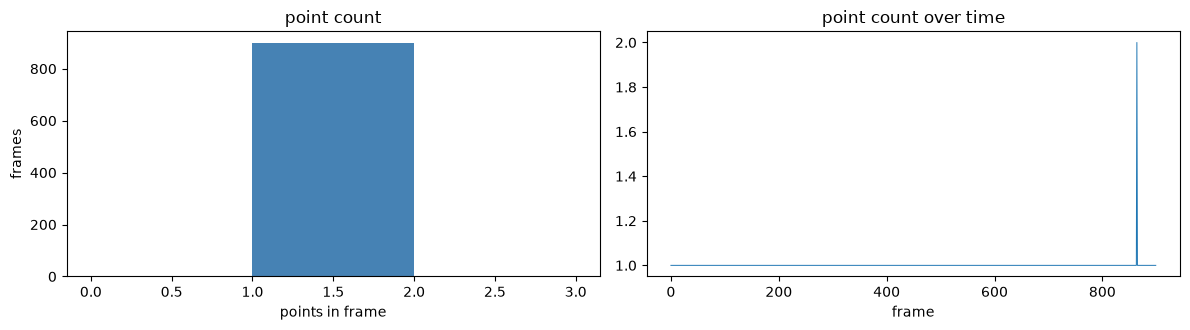

In [41]:
npts = np.array([len(np.asarray(f.output.pointcloud)) for f in frames])
print(f"points per frame: mean {npts.mean():.1f}, median {np.median(npts):.0f}, "
      f"max {npts.max()}, empty frames {100 * (npts == 0).mean():.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(npts, bins=range(0, npts.max() + 2), color="steelblue")
ax[0].set_xlabel("points in frame"); ax[0].set_ylabel("frames"); ax[0].set_title("point count")
ax[1].plot(npts, lw=0.7)
ax[1].set_xlabel("frame"); ax[1].set_title("point count over time")
plt.tight_layout()
plt.show()

A handful of points per frame, against a walking person's 40-90. Whatever you
build has to cope with that.

## 7. Where the points land

total points: 901


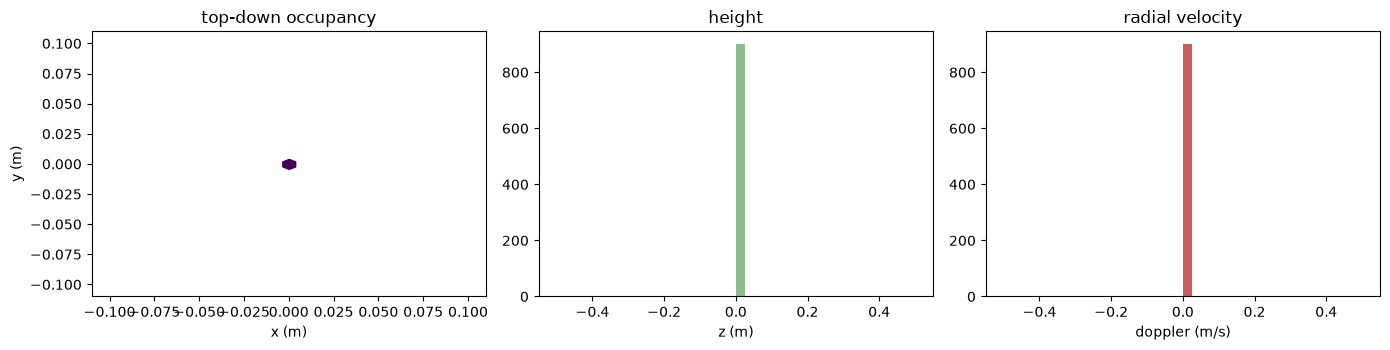

In [42]:
pcs = [np.asarray(f.output.pointcloud, dtype=float) for f in frames]
pcs = [p for p in pcs if p.ndim == 2 and len(p)]
allp = np.vstack(pcs) if pcs else np.zeros((0, 7))
print("total points:", len(allp))

if len(allp):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].hexbin(allp[:, 0], allp[:, 1], gridsize=28, cmap="viridis", mincnt=1)
    ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("y (m)"); ax[0].set_title("top-down occupancy")
    ax[1].hist(allp[:, 2], bins=40, color="darkseagreen")
    ax[1].set_xlabel("z (m)"); ax[1].set_title("height")
    ax[2].hist(allp[:, 3], bins=40, color="indianred")
    ax[2].set_xlabel("doppler (m/s)"); ax[2].set_title("radial velocity")
    plt.tight_layout()
plt.show()

Doppler piles up at zero — a still person. That is the signal you are working
with, and it is why a movement-based detector finds nothing here.

## 8. Comparing recordings

Different configs, different rooms, different people. Here is one mid-recording
frame from several recordings side by side.

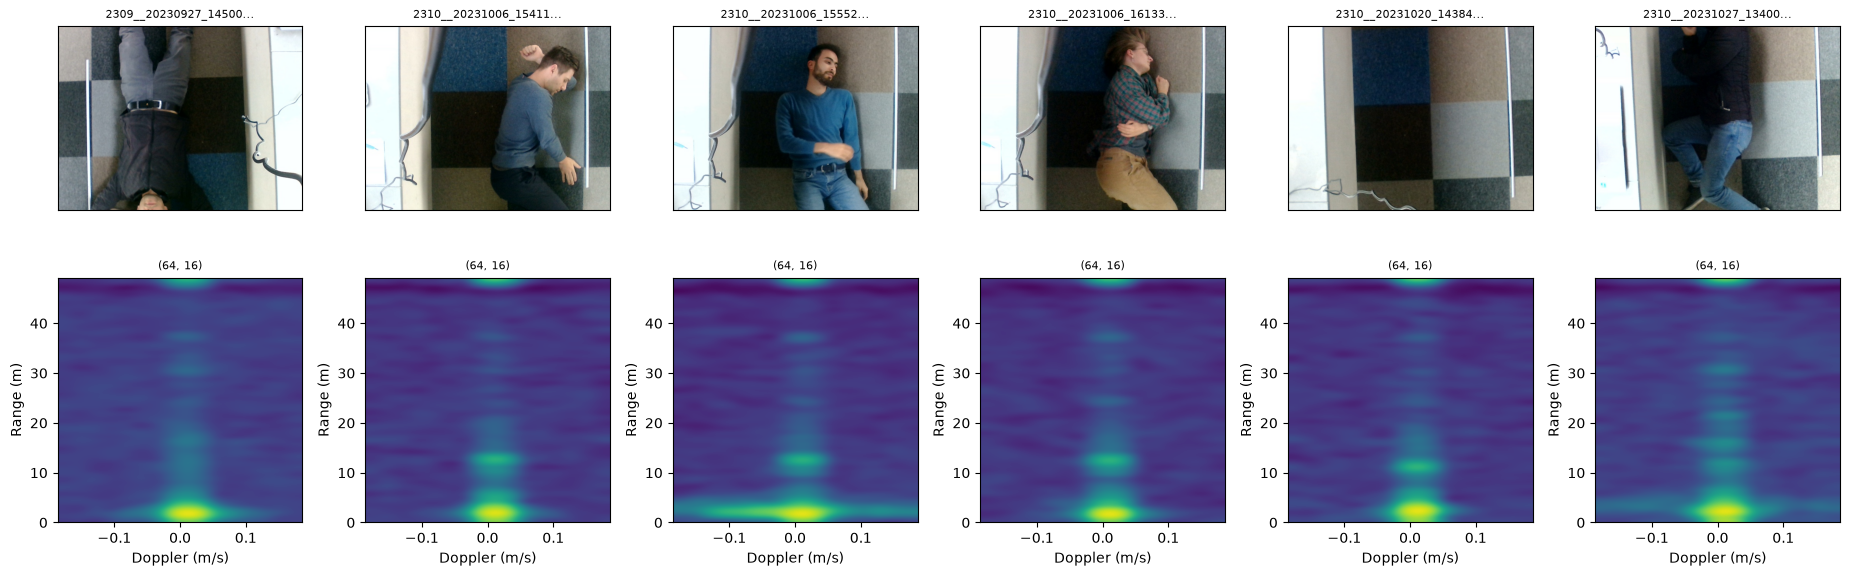

In [43]:
picks = present.dataset.tolist()[:6]
n = len(picks)
fig, axes = plt.subplots(2, n, figsize=(3.1 * n, 6.4))
axes = np.atleast_2d(axes)
for j, rec in enumerate(picks):
    d = TLVDataset(rec_dir(rec))
    fr = list(d)
    if not fr:
        continue
    f = fr[len(fr) // 2]
    img = np.asarray(f.image)
    if img.size:
        axes[0, j].imshow(img)
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[0, j].set_title(rec[:20] + "...", fontsize=8)

    h = np.asarray(f.output.range_doppler_heatmap, dtype=float)
    sensor = d.config.sensor() if d.config else None
    if sensor is not None:
        RangeDoppler(h, sensor)._plot_heatmap(axes[1, j], plot_colorbar=False)
    else:
        axes[1, j].imshow(np.log1p(h), aspect="auto", cmap="magma")
        axes[1, j].set_xlabel("doppler bin")
        axes[1, j].set_ylabel("range bin")
    axes[1, j].set_title(f"{h.shape}", fontsize=8)
plt.tight_layout()
plt.show()

## 9. Labels, where they exist

Some recordings carry labels under `labels/`. They came from more than one tool
over the campaign and the boundaries around a posture change are approximate, so
treat them as a reference rather than ground truth.

```
0 = moving    1 = back    2 = side    3 = front    99 = standing
```

In [44]:
NAMES = {0: "moving", 1: "back", 2: "side", 3: "front", 99: "standing"}

def load_labels(rec):
    '''Best-effort per-frame labels for a recording, or None.'''
    d = rec_dir(rec)
    for cand in ("state_labels.csv", "labels.csv", "3_classes.csv", "2_classes.csv"):
        p = os.path.join(d, "labels", cand)
        if os.path.isfile(p):
            df = pd.read_csv(p)
            col = "label" if "label" in df.columns else df.columns[-1]
            return pd.to_numeric(df[col], errors="coerce").values, cand
    npys = glob.glob(os.path.join(d, "**", "*.npy"), recursive=True)
    if npys:
        # plain integer arrays, so no allow_pickle (which would be a code-execution path)
        return np.load(npys[0]).astype(float), os.path.basename(npys[0])
    return None, None


labelled = present[present.has_labels].dataset.tolist()
print("recordings with labels here:", len(labelled))
for rec in labelled[:5]:
    lab, src = load_labels(rec)
    if lab is None:
        continue
    counts = {NAMES.get(int(v), int(v)): int((lab == v).sum()) for v in np.unique(lab[~np.isnan(lab)])}
    print(f"  {rec[:44]:46} {src:20} {counts}")

recordings with labels here: 14
  2310__20231006_154117                          labels.npy           {'moving': 403, 'back': 1091, 'side': 1106}
  2311__20231115_135843                          state_labels.csv     {'moving': 535, 'back': 236, 'side': 467, 'front': 263, 'standing': 99}
  2311__20231115_140642                          state_labels.csv     {'moving': 795, 'back': 193, 'side': 343, 'front': 193, 'standing': 76}
  2311__20231120_144541                          state_labels.csv     {'moving': 1071, 'back': 151, 'side': 269, 'front': 137, 'standing': 272}
  2311__20231120_145729                          state_labels.csv     {'moving': 641, 'back': 286, 'side': 520, 'front': 238, 'standing': 115}


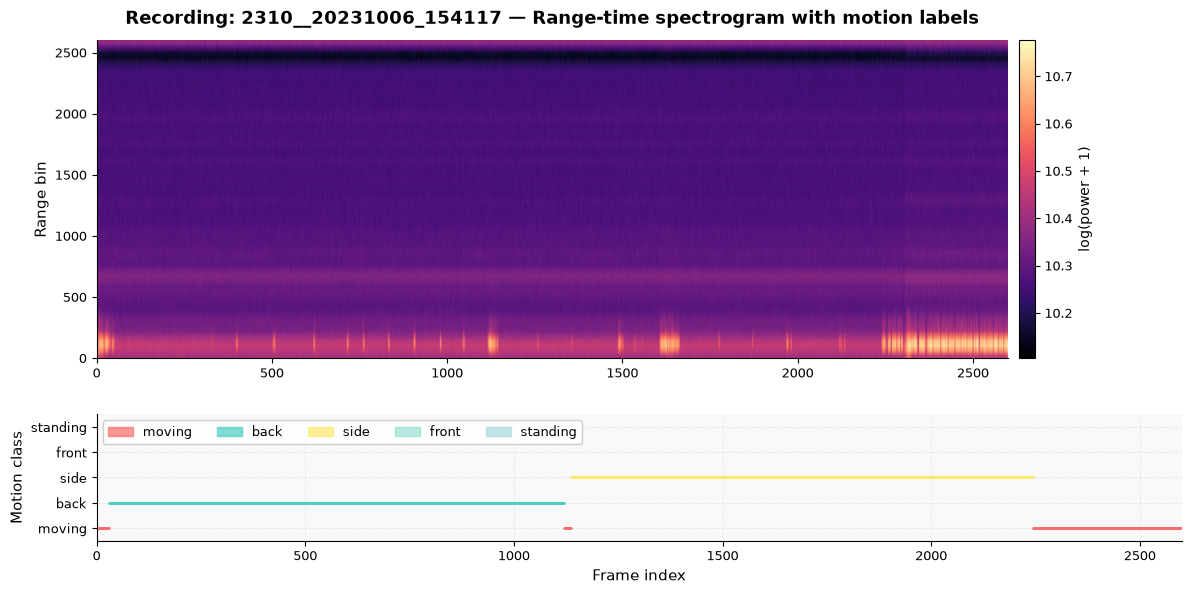

In [45]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

NAMES = {0: "moving", 1: "back", 2: "side", 3: "front", 99: "standing"}

# Create reverse mapping for remapped values
LABEL_REMAP = {0: 0, 1: 1, 2: 2, 3: 3, 99: 4}
NAMES_REMAPPED = {v: NAMES[k] for k, v in LABEL_REMAP.items()}

if labelled:
    rec = labelled[0]
    lab, src = load_labels(rec)
    d = TLVDataset(rec_dir(rec))
    fr = list(d)
    n = min(len(fr), len(lab))
    rt = range_time(fr[:n])

    # Remap labels so standing (99) becomes 4
    lab_remapped = np.array([LABEL_REMAP[int(l)] for l in lab[:n]])

    # Create figure with better proportions and spacing
    fig = plt.figure(figsize=(14, 6.5))
    gs = fig.add_gridspec(2, 1, height_ratios=[3, 1.2], hspace=0.25)
    ax0 = fig.add_subplot(gs[0])
    ax1 = fig.add_subplot(gs[1], sharex=ax0)

    # Range-time spectrogram
    im = ax0.imshow(
        np.log1p(rt).T,
        aspect="auto",
        cmap="magma",
        origin="lower",
        extent=[0, n, 0, rt.shape[0]],
        interpolation="bilinear",
    )
    ax0.set_ylabel("Range bin", fontsize=11, fontweight=500)
    ax0.set_title(
        f"Recording: {rec} — Range-time spectrogram with motion labels",
        fontsize=13,
        fontweight=600,
        pad=12,
    )
    cbar = plt.colorbar(im, ax=ax0, label="log(power + 1)", pad=0.01)
    cbar.ax.tick_params(labelsize=9)

    # Create colormap for labels
    label_colors = {
        0: "#FF6B6B",  # moving - red
        1: "#4ECDC4",  # back - teal
        2: "#FFE66D",  # side - gold
        3: "#95E1D3",  # front - mint
        4: "#A8DADC",  # standing - light blue (remapped from 99)
    }

    # Plot label changes with color coding
    for i in range(n - 1):
        label_val = int(lab_remapped[i])
        color = label_colors.get(label_val, "#999")
        ax1.plot(
            [i, i + 1],
            [label_val, label_val],
            color=color,
            linewidth=2,
            solid_capstyle="round",
        )

    # Styling
    ax1.set_yticks(sorted(NAMES_REMAPPED.keys()))
    ax1.set_yticklabels(
        [NAMES_REMAPPED[k] for k in sorted(NAMES_REMAPPED.keys())], fontsize=10
    )
    ax1.set_xlabel("Frame index", fontsize=11, fontweight=500)
    ax1.set_ylabel("Motion class", fontsize=11, fontweight=500)
    ax1.set_ylim(-0.5, 4.5)
    ax1.grid(alpha=0.2, linestyle="--", linewidth=0.7)
    ax1.set_facecolor("#f9f9f9")

    # Create legend for label colors
    legend_patches = [
        mpatches.Patch(color=label_colors[k], label=f"{NAMES_REMAPPED[k]}", alpha=0.7)
        for k in sorted(NAMES_REMAPPED.keys())
    ]
    ax1.legend(
        handles=legend_patches,
        loc="upper left",
        ncol=5,
        fontsize=9,
        framealpha=0.95,
        frameon=True,
    )

    # General styling
    fig.patch.set_facecolor("white")
    for ax in [ax0, ax1]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(labelsize=9)

    plt.show()


Where the label track holds steady, the range-time band is flat; the `moving`
stretches line up with the smeared parts.

## 10. Reading the raw file, no package

If you would rather not use the reader at all, a chunk is a plain DataFrame:
`frame` holds the raw radar payload, `image` the JPEG bytes.

In [46]:
chunk = sorted(glob.glob(os.path.join(rec_dir(REC), "*.h5")))[0]
raw = pd.read_hdf(chunk)
print(os.path.basename(chunk), "->", list(raw.columns), f"{len(raw)} rows")
raw.head(3)

data_0.h5 -> ['frame', 'timestamp', 'image'] 100 rows


,frame,timestamp,image
0,"[2, 1, 4, 3, 6, 5, 8, 7, 0, 0, 6, 3, 64, 8, 0,...",2023-09-27 12:50:24.502987,"[255, 216, 255, 224, 0, 16, 74, 70, 73, 70, 0,..."
1,"[2, 1, 4, 3, 6, 5, 8, 7, 0, 0, 6, 3, 64, 8, 0,...",2023-09-27 12:50:24.662259,"[255, 216, 255, 224, 0, 16, 74, 70, 73, 70, 0,..."
2,"[2, 1, 4, 3, 6, 5, 8, 7, 0, 0, 6, 3, 64, 8, 0,...",2023-09-27 12:50:24.869490,"[255, 216, 255, 224, 0, 16, 74, 70, 73, 70, 0,..."


## Where to go next

Some directions worth trying:

- **Is anyone there?** Separate the empty-room recordings from the occupied
  ones. The `*_environment` recordings are background with nobody in the scene.
- **Where are they?** The range-time plot shows the person as a band; turning
  that into a position estimate is a good warm-up.
- **Which way are they lying?** The hard one. Start from the heatmap, and mind
  the differing geometries between recordings.
- **Does it survive a room change?** `room2` is the same rig elsewhere. Anything
  that works in `room1` and collapses in `room2` has learnt the room, not the
  person.

Whatever you build, split by **recording** rather than by frame: at ~18 fps,
neighbouring frames are near-copies, and mixing them across a split will make a
weak model look excellent.

# Is anyone there?

In [47]:
def filter_func(x, room_id="room1", heatmap_shape="(64, 16)"):
    return (x["room"] == room_id) & (x["heatmap"] == heatmap_shape)

# Train from room 1
train_ds = present[filter_func(present, room_id="room1")]

# The `*_environment` recordings are background with nobody in the scene.
empty_room = train_ds[train_ds["dataset"].str.contains("_environment")]

# Evaluate on room 2 (need to be able to find people in different environments)
test_ds = present[filter_func(present, room_id="room2")]

In [48]:
train_ds

,dataset,room,source_path,h5_files,frames,size_mb,recorded,has_labels,posture_frames,rec,heatmap,cfg,present
0,2309__20230927_145000,room1,D:/TLV/2309/20230927_145000,9,900,86.0,2023-09-27 12:51,False,0,2309__20230927_145000,"(64, 16)",Experiment_1.cfg,True
1,2310__20231006_154117,room1,D:/TLV/2310/20231006_154117,26,2600,245.7,2023-10-06 13:45,True,2197,2310__20231006_154117,"(64, 16)",Experiment_1.cfg,True
2,2310__20231006_155527,room1,D:/TLV/2310/20231006_155527,15,1500,138.8,2023-10-06 13:57,False,0,2310__20231006_155527,"(64, 16)",Experiment_1.cfg,True
3,2310__20231006_161334,room1,D:/TLV/2310/20231006_161334,15,1500,143.8,2023-10-06 14:15,False,0,2310__20231006_161334,"(64, 16)",Experiment_1.cfg,True
4,2310__20231020_143847,room1,D:/TLV/2310/20231020_143847,15,1500,128.7,2023-10-20 12:39,False,0,2310__20231020_143847,"(64, 16)",Experiment_1.cfg,True
5,2310__20231027_134002,room1,D:/TLV/2310/20231027_134002,18,1800,176.6,2023-10-27 11:45,False,0,2310__20231027_134002,"(64, 16)",Experiment_1.cfg,True
6,2310__20231027_140700,room1,D:/TLV/2310/20231027_140700,17,1700,147.0,2023-10-27 12:12,False,0,2310__20231027_140700,"(64, 16)",Experiment_1.cfg,True
7,2310__20231027_142000,room1,D:/TLV/2310/20231027_142000,15,1500,135.9,2023-10-27 12:20,False,0,2310__20231027_142000,"(64, 16)",Experiment_1.cfg,True
8,2310__20231027_143141,room1,D:/TLV/2310/20231027_143141,20,2000,186.6,2023-10-27 12:37,False,0,2310__20231027_143141,"(64, 16)",Experiment_1.cfg,True
9,2310__20231027_150820,room1,D:/TLV/2310/20231027_150820,17,1700,156.4,2023-10-27 13:13,False,0,2310__20231027_150820,"(64, 16)",Experiment_1.cfg,True


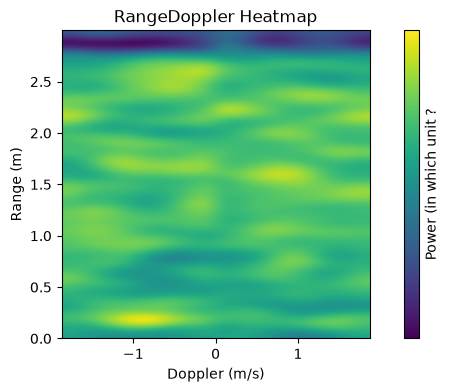

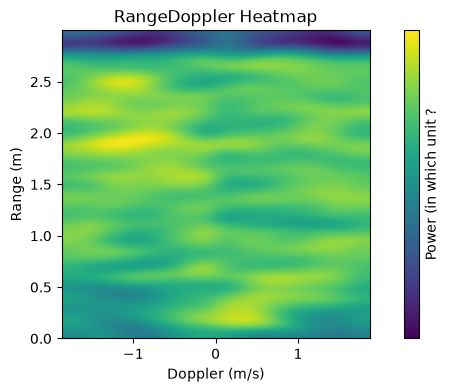

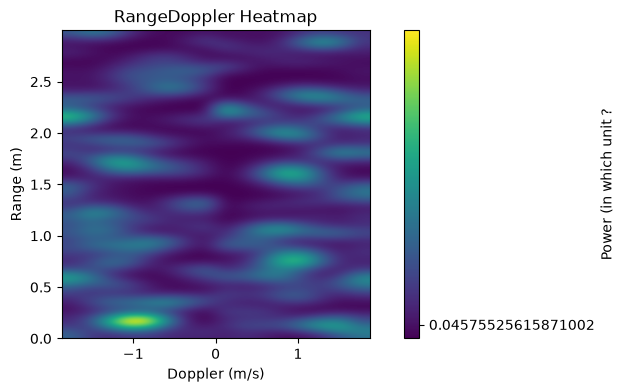

In [49]:
from scipy.ndimage import gaussian_filter

def show_doppler_ftt(ds, bg=None):
    frames = list(ds)
    sensor = ds.config.sensor() if ds.config else None

    f = frames[len(frames) // 2] # frame from the middle of the recording
    heat = np.asarray(f.output.range_doppler_heatmap, dtype=float)

    if bg is not None:
        frames_bg = list(bg)
        # average all the frames
        # average all the frames element-wise
        heatmaps_bg = np.asarray(
            [f.output.range_doppler_heatmap for f in frames_bg], dtype=float
        )
        heat_bg = heatmaps_bg.mean(axis=0)

        # subtract the background noise from the recording
        heat = np.clip(heat - heat_bg, 0, None)

    # gaussian blur (remove echoes)
    heat = gaussian_filter(heat, sigma=1)

    fig, ax = plt.subplots()
    if sensor is not None:
        RangeDoppler(heat, sensor)._plot_heatmap(ax)
    else:
        im = ax.imshow(np.log1p(heat), aspect="auto", cmap="magma")
        ax.set_xlabel("doppler bin")
        ax.set_ylabel("range bin")
        plt.colorbar(im, ax=ax, label="log power")
    plt.show()


# recording to ds
# NOTE: bg subtraction only makes sense between recordings from the SAME
# radar config. Pick foreground/background recordings
# that share the same `cfg`; idx 23/24 and idx 25 are the same session
# (Thursday(02.11)_Exp_1.cfg).
assert train_ds.loc[23, "cfg"] == empty_room.loc[25, "cfg"]
train_rec = train_ds.dataset[23]
empty_room_rec = empty_room.dataset[25]

myds = TLVDataset(rec_dir(train_rec))
empty_room_ds = TLVDataset(rec_dir(empty_room_rec))

show_doppler_ftt(myds)
show_doppler_ftt(empty_room_ds)
show_doppler_ftt(myds, empty_room_ds)


In [50]:
train_rec

'Config_2__Exp_1__11_02_2023__reduceClutter_Artem'

In [51]:
import matplotlib.animation as animation
from IPython.display import HTML

def animate_doppler(ds, max_frames=None, interval=200):
    '''Play a recording's range-doppler heatmap frame by frame. interval is ms/frame
    (this dataset runs at 5 fps).'''
    sensor = ds.config.sensor() if ds.config else None
    frames = list(ds)[:max_frames]

    # need to use fftshift to center doppler values on 0m/s
    # need to use flipud to make far away objects be high on the y-axis
    heats = [
        np.flipud(np.fft.fftshift(
            np.log1p(np.asarray(f.output.range_doppler_heatmap, dtype=float)), axes=1))
        for f in frames
    ]

    # normalize the values across the recording
    vmin = min(h.min() for h in heats)
    vmax = max(h.max() for h in heats)

    extent = None
    if sensor is not None:
        extent = (min(sensor.doppler_bins), max(sensor.doppler_bins), 0, max(sensor.range_bins))

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(heats[0], aspect="auto", cmap="magma", vmin=vmin, vmax=vmax, extent=extent)
    if extent is not None:
        ax.set_aspect(abs((extent[1] - extent[0]) / (extent[3] - extent[2])))
        ax.set_xlabel("Doppler (m/s)")
        ax.set_ylabel("Range (m)")
    else:
        ax.set_xlabel("doppler bin")
        ax.set_ylabel("range bin")
    title = ax.set_title(f"frame 0 / {len(heats)}")
    plt.colorbar(im, ax=ax, label="log power")

    def update(i):
        im.set_data(heats[i])
        title.set_text(f"frame {i} / {len(heats)}")
        return im, title

    anim = animation.FuncAnimation(fig, update, frames=len(heats), interval=interval, blit=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())


# play the empty-room recording to see what pure noise/clutter looks like over time
animate_doppler(TLVDataset(rec_dir(empty_room_rec)), max_frames=30)


## Comparing smoothing methods

The first method I explored (above) was background subtraction: average every
frame of an empty-room recording and subtract that average from each frame of
the recording I care about, clipping negative values to 0. I've added it here
as `bg_subtract` so it can be compared directly against the others.

Only the `Config_2` noise/reduceClutter sessions shipped a matching
`*_environment` recording sharing the same radar `cfg` — for every other
recording there is no genuine background to subtract, so `bg_subtract` (and
any chain that includes it) is skipped for those rather than subtracting an
unrelated empty room.

Methods can be chained by passing a tuple instead of a single name, e.g.
`("bg_subtract", "ema")` first removes the background then EMA-smooths the
result, or `("ema", "gaussian")` smooths over time then blurs each frame.

I noticed two types of noise:
1. "TV static" noise from the background
2. "large flickers" across frames

To counter the TV static (blur, median, bg subtraction). To counter the flickering (rolling average, exponential moving average)

To see how much power is in the frame I use RMS, a large value means more activity.

In [66]:
from scipy.ndimage import gaussian_filter, median_filter

def load_heatmap_stack(frames):
    '''(n_frames, range_bins, doppler_bins) array of raw heatmaps.'''
    return np.stack([np.asarray(f.output.range_doppler_heatmap, dtype=float) for f in frames])


def load_camera_stack(frames):
    '''(n_frames, H, W, 3) array of camera images, frame-aligned with load_heatmap_stack
    when given the SAME `frames` list.'''
    return np.stack([np.asarray(f.image) for f in frames])


def load_bg_stack(rec, max_frames=None):
    '''Heatmap stack for the "*_environment" recording that matches `rec`'s
    radar cfg (bg subtraction only makes sense between recordings from the
    same cfg). Raises if `rec` has no matching empty-room recording, rather
    than silently subtracting an unrelated background.'''
    cfg = present.loc[present["dataset"] == rec, "cfg"].iloc[0]
    candidates = empty_room[empty_room["cfg"] == cfg]
    if candidates.empty:
        raise ValueError(
            f"no *_environment recording shares cfg {cfg!r} with {rec!r}; "
            "bg_subtract isn't valid for this recording"
        )
    bg_rec = candidates.dataset.iloc[0]
    bg_frames = list(TLVDataset(rec_dir(bg_rec)))[:max_frames]
    return load_heatmap_stack(bg_frames)


def smooth_stack(heats, method, bg=None):
    '''Apply one smoothing method, or a chain of them, to a (frames, range,
    doppler) stack. `method` is a single method name, or a tuple/list of names
    applied in order -- e.g. ("bg_subtract", "ema") removes the background
    first, then EMA-smooths the result. `bg` is only used by "bg_subtract"
    steps.'''
    if isinstance(method, (list, tuple)):
        for step in method:
            heats = smooth_stack(heats, step, bg=bg)
        return heats
    if method == "none":
        return heats
    if method == "bg_subtract":  # remove averaged empty-room background noise
        if bg is None:
            raise ValueError('bg_subtract requires bg=<empty-room heatmap stack>')
        bg_mean = bg.mean(axis=0)
        return np.clip(heats - bg_mean, 0, None)
    if method == "gaussian":     # spatial: blur within each frame
        return np.stack([gaussian_filter(h, sigma=1) for h in heats])
    if method == "median":       # spatial: kill speckle within each frame
        return np.stack([median_filter(h, size=3) for h in heats])
    if method == "moving_avg":   # temporal: rolling mean over time, per bin
        window = 5
        pad = window // 2
        padded = np.pad(heats, ((pad, pad), (0, 0), (0, 0)), mode="edge")
        kernel = np.ones(window) / window
        return np.apply_along_axis(lambda x: np.convolve(x, kernel, mode="valid"), axis=0, arr=padded)
    if method == "ema":          # temporal: exponential moving average over time
        alpha = 0.3
        out = np.empty_like(heats)
        out[0] = heats[0]
        for i in range(1, len(heats)):
            out[i] = alpha * heats[i] + (1 - alpha) * out[i - 1]
        return out
    raise ValueError(f"unknown method {method!r}")


def method_label(method):
    '''Display name for a method or chain, e.g. ("bg_subtract", "ema") -> "bg_subtract+ema".'''
    return method if isinstance(method, str) else "+".join(method)


def uses_bg(method):
    '''Whether a method or chain includes a "bg_subtract" step.'''
    if isinstance(method, str):
        return method == "bg_subtract"
    return any(uses_bg(step) for step in method)


def frame_energy(heats):
    '''RMS energy per frame: sqrt(mean(value**2)) over the (range, doppler) bins.
    This is the raw power level in each frame'''
    return np.sqrt(np.mean(heats ** 2, axis=(1, 2)))

In [67]:
def animate_doppler_grid(named_stacks, camera=None, interval=200, sensor=None):
    '''Play several (frames, range, doppler) stacks side by side, frame-synced.
    Pass `camera` (frames x H x W x 3) to show the camera feed as the first panel,
    so you can see what actually happened next to each smoothing method.

    Each stack is oriented the same way as RangeDoppler._plot_heatmap: doppler
    centred on 0 m/s (fftshift) and range increasing away from the sensor
    (flipud). Pass `sensor` to also label the axes in physical units.'''
    names = list(named_stacks)
    logged = {
        name: np.flip(np.fft.fftshift(np.log1p(named_stacks[name]), axes=2), axis=1)
        for name in names
    }
    n_frames = min(h.shape[0] for h in logged.values())
    if camera is not None:
        n_frames = min(n_frames, len(camera))

    extent = None
    if sensor is not None:
        extent = (min(sensor.doppler_bins), max(sensor.doppler_bins), 0, max(sensor.range_bins))

    n_panels = len(names) + (1 if camera is not None else 0)
    fig, axes = plt.subplots(1, n_panels, figsize=(3.4 * n_panels, 4.2))
    axes = np.atleast_1d(axes)

    ims = []
    ax_i = 0
    if camera is not None:
        cam_im = axes[ax_i].imshow(camera[0])
        axes[ax_i].set_title("camera")
        axes[ax_i].set_xticks([]); axes[ax_i].set_yticks([])
        ims.append(("camera", cam_im))
        ax_i += 1
    for name in names:
        h = logged[name]
        im = axes[ax_i].imshow(h[0], aspect="auto", cmap="magma", vmin=h.min(), vmax=h.max(), extent=extent)
        axes[ax_i].set_title(name)
        axes[ax_i].set_xlabel("Doppler (m/s)" if extent is not None else "doppler bin")
        ims.append((name, im))
        ax_i += 1
    axes[1 if camera is not None else 0].set_ylabel("Range (m)" if extent is not None else "range bin")
    suptitle = fig.suptitle("frame 0")
    plt.tight_layout()

    def update(i):
        for name, im in ims:
            im.set_data(camera[i] if name == "camera" else logged[name][i])
        suptitle.set_text(f"frame {i} / {n_frames}")
        return [im for _, im in ims] + [suptitle]

    anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=interval, blit=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())

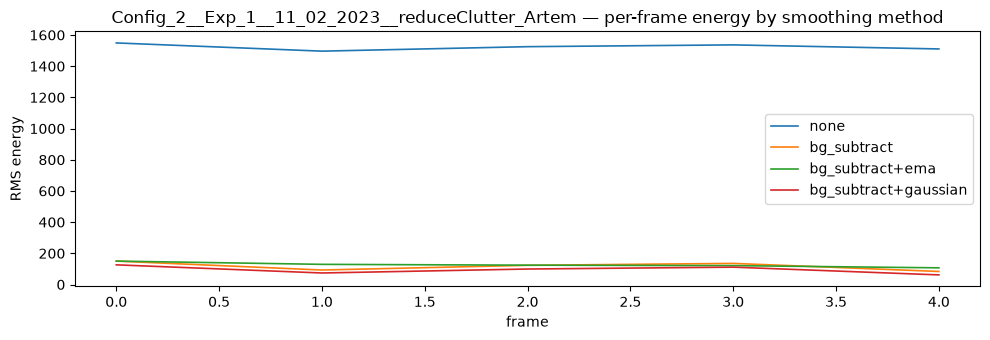

In [74]:
METHODS = [
    "none",
    "bg_subtract",
    # "gaussian",
    # "median",
    # "moving_avg",
    # "ema",
    ("bg_subtract", "ema"),
    ("bg_subtract", "gaussian")
    # ("ema", "gaussian"),
]
MAX_FRAMES = 5 # use 200 for inspection

REC_TO_PLAY = train_rec  # a Config_2 recording -- has a matching *_environment background
# REC_TO_PLAY = train_ds.dataset[2]  # swap to compare on another occupied recording
play_ds = TLVDataset(rec_dir(REC_TO_PLAY))
sensor = play_ds.config.sensor() if play_ds.config else None
frames = list(play_ds)[:MAX_FRAMES]

raw = load_heatmap_stack(frames)
camera = load_camera_stack(frames)

methods = list(METHODS)
try:
    bg = load_bg_stack(REC_TO_PLAY, max_frames=MAX_FRAMES)
except ValueError as e:
    print(f"skipping bg_subtract methods: {e}")
    bg = None
    methods = [m for m in methods if not uses_bg(m)]

stacks = {method_label(m): smooth_stack(raw, m, bg=bg) for m in methods}

fig, ax = plt.subplots(figsize=(10, 3.5))
for m in methods:
    ax.plot(frame_energy(stacks[method_label(m)]), label=method_label(m), lw=1.2)
ax.set_xlabel("frame")
ax.set_ylabel("RMS energy")
ax.set_title(f"{REC_TO_PLAY} — per-frame energy by smoothing method")
ax.legend()
plt.tight_layout()
plt.show()

animate_doppler_grid(stacks, camera=camera, interval=MAX_FRAMES, sensor=sensor)

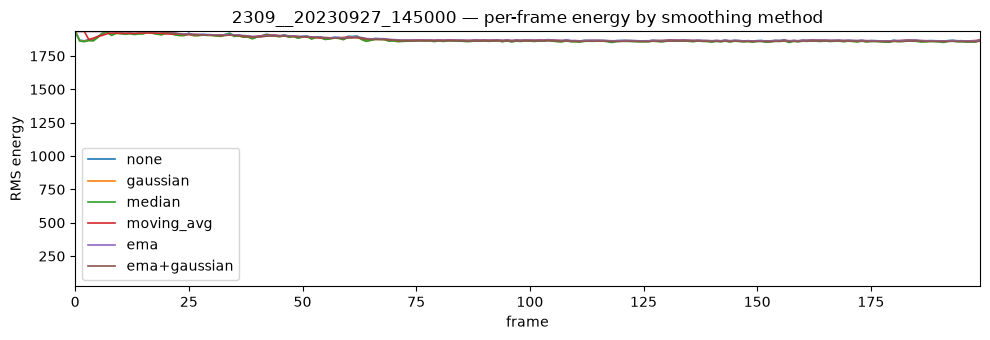

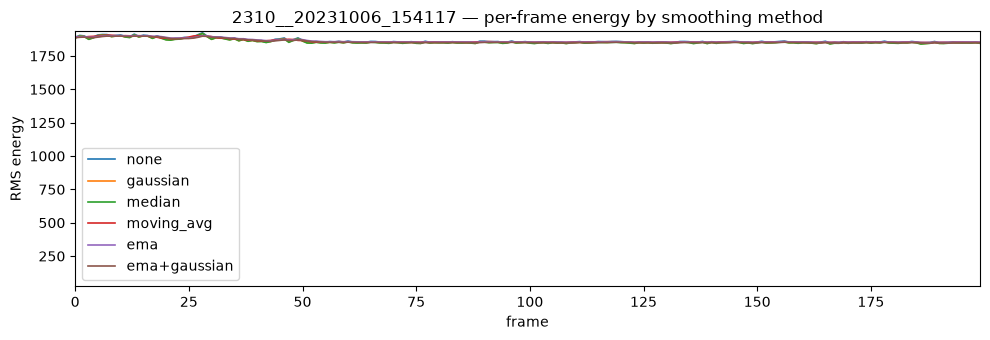

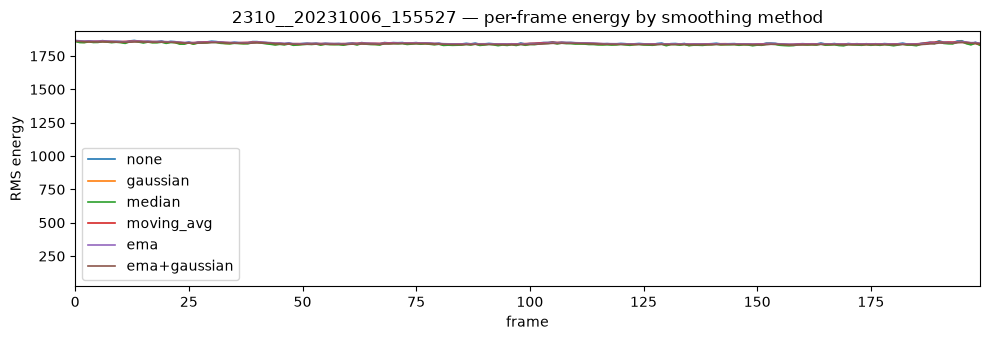

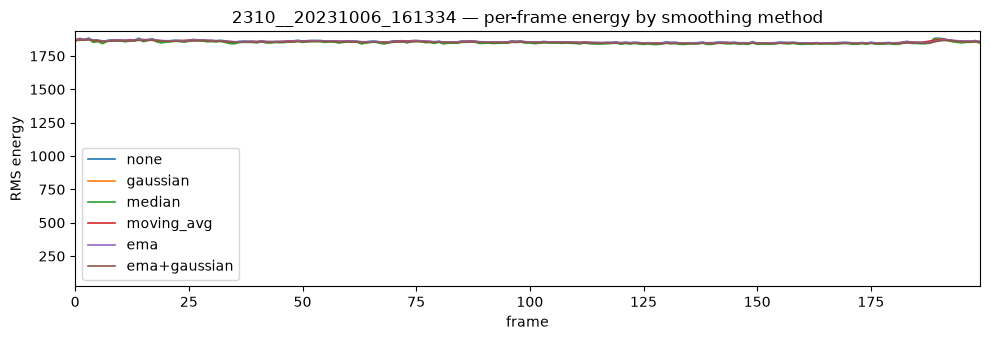

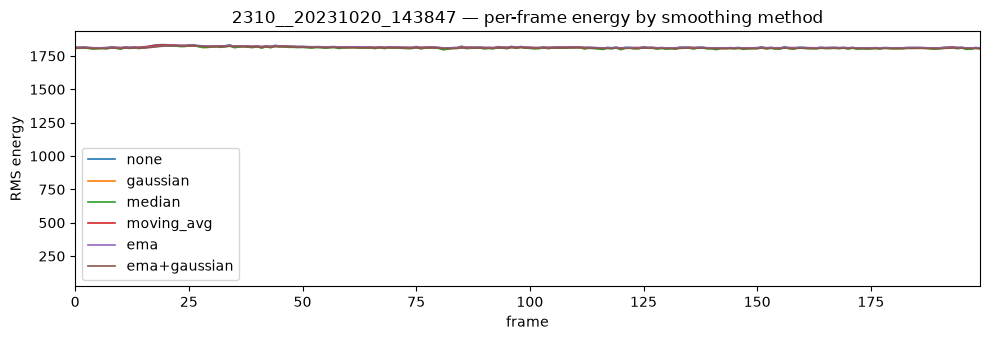

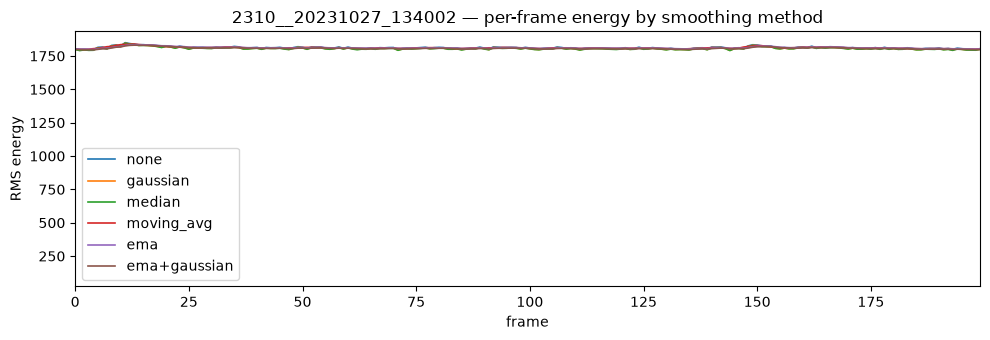

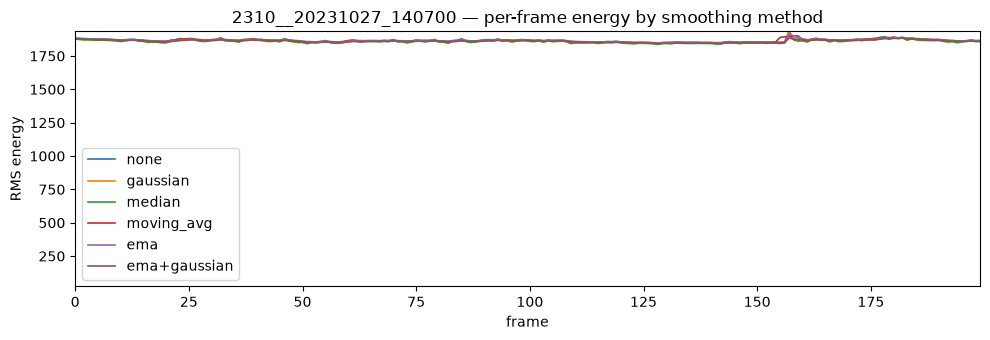

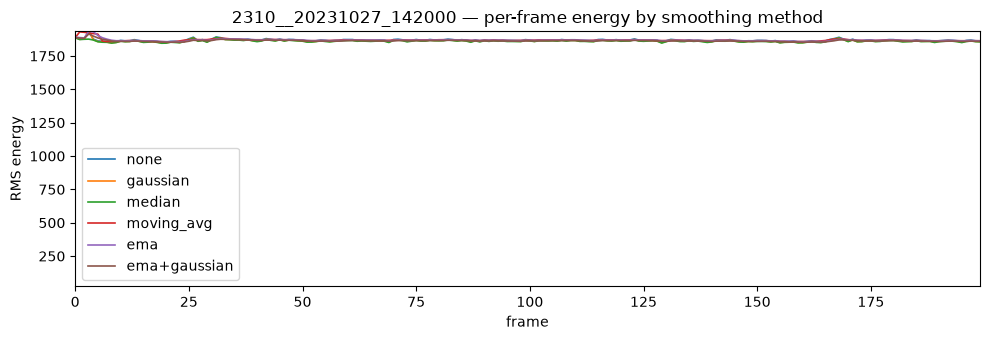

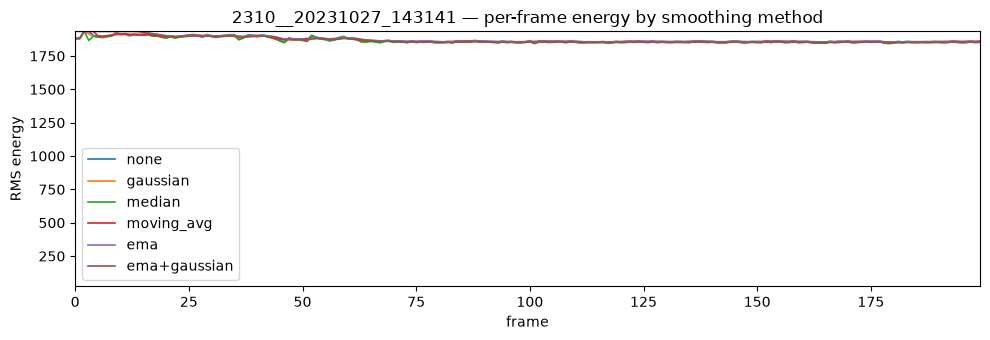

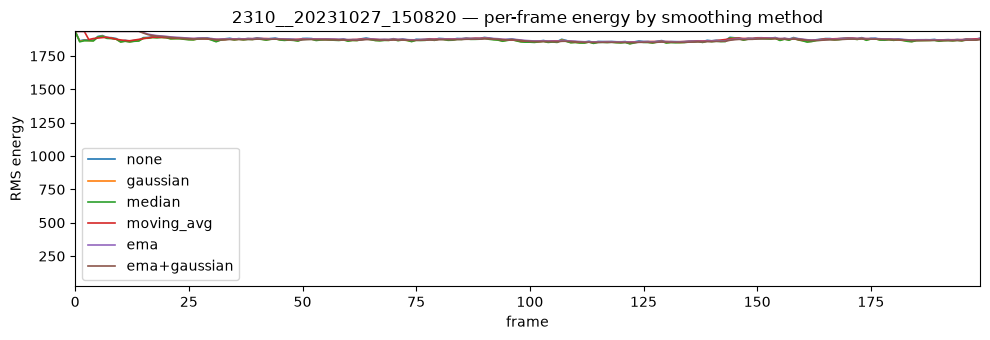

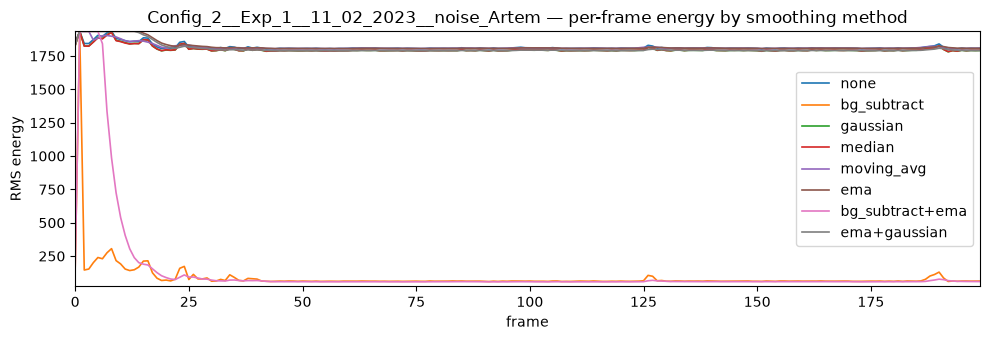

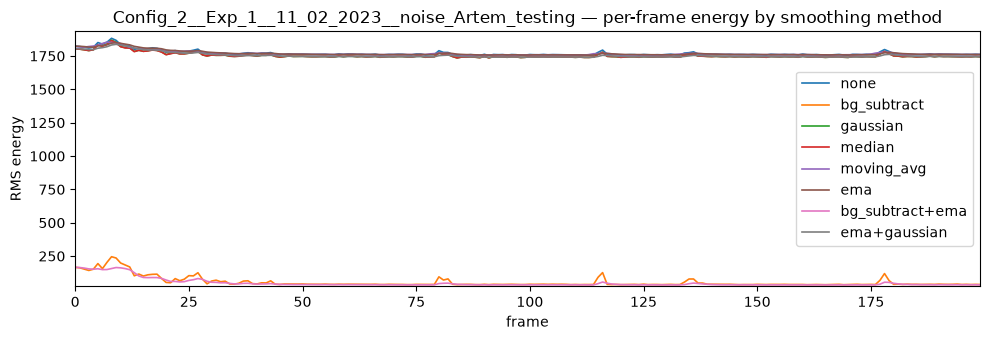

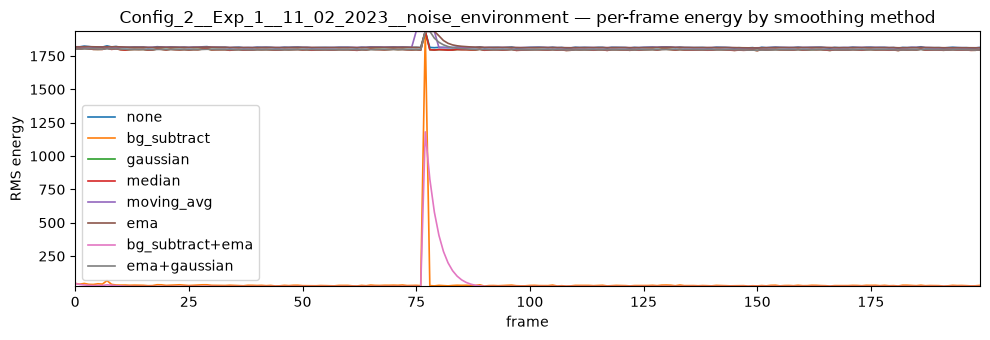

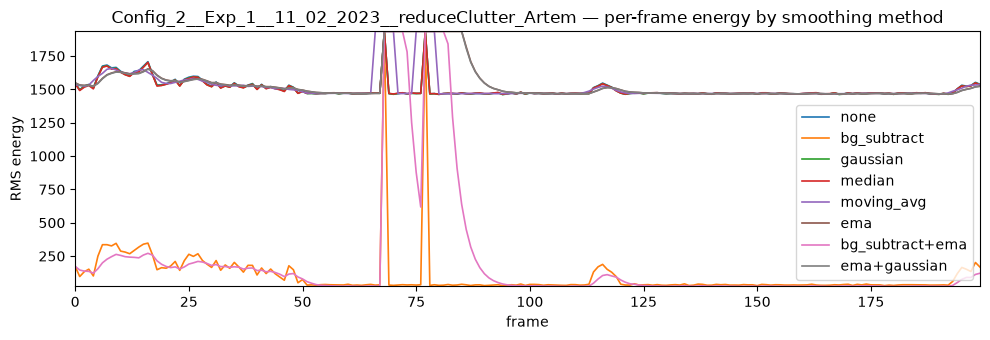

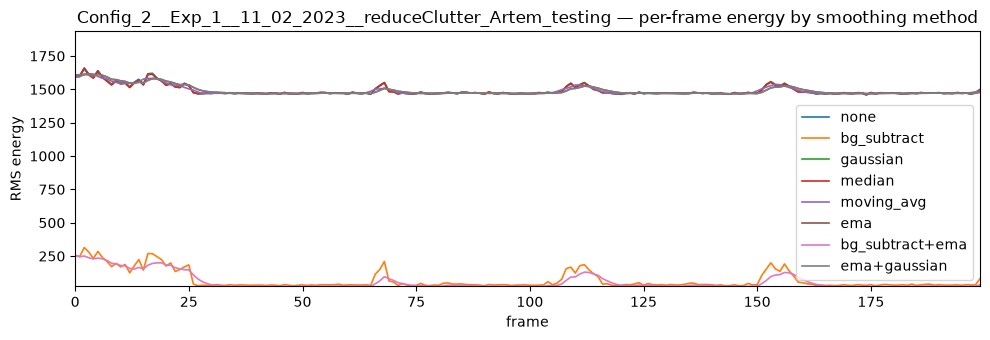

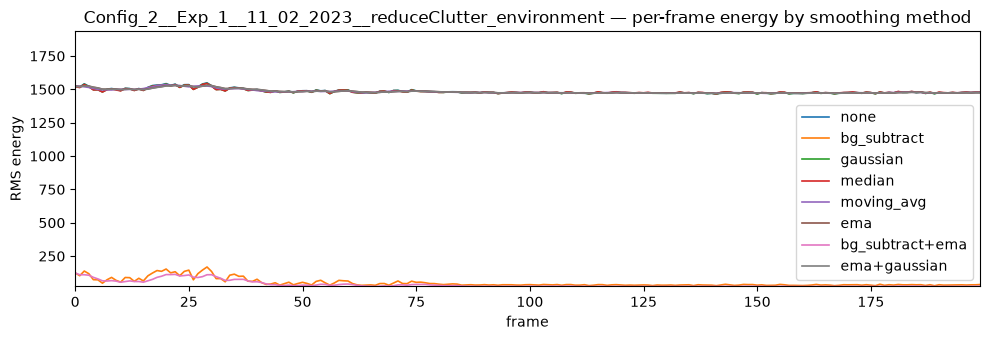

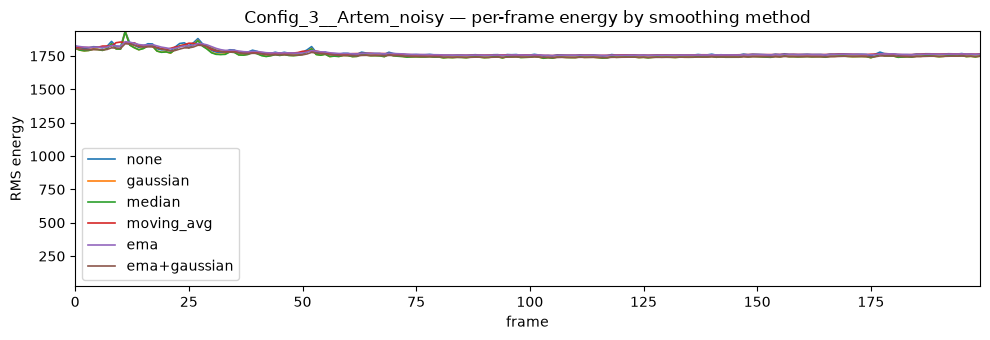

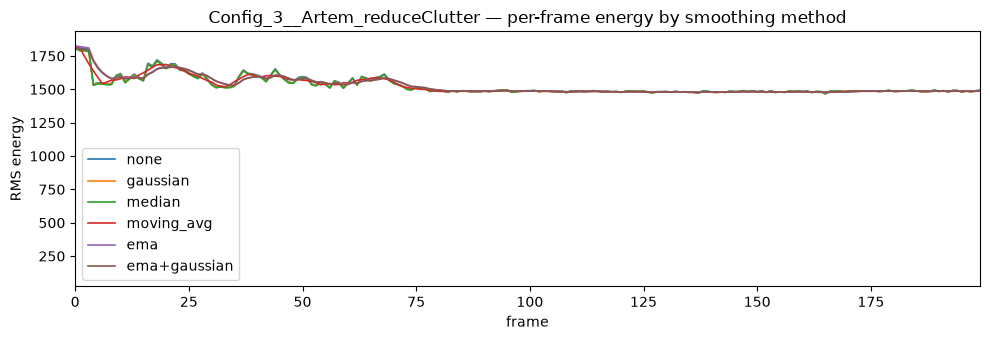

In [69]:
# to plot the datastes on the same x- y-range
# NOTE: only the Config_2 noise/reduceClutter recordings shipped a matching
# *_environment background, so any method chain that includes bg_subtract is
# skipped for every other recording.
all_energies = []
max_len = 0
for rec in train_ds.dataset:
    play_ds = TLVDataset(rec_dir(rec))
    frames = list(play_ds)[:200]
    raw = load_heatmap_stack(frames)

    methods = list(METHODS)
    try:
        bg = load_bg_stack(rec, max_frames=200)
    except ValueError:
        bg = None
        methods = [m for m in methods if not uses_bg(m)]

    stacks = {method_label(m): smooth_stack(raw, m, bg=bg) for m in methods}
    for m in methods:
        e = frame_energy(stacks[method_label(m)])
        all_energies.append(e)
        max_len = max(max_len, len(e))

all_vals = np.concatenate(all_energies)

# dont render huge spikes (above 99th percentile)
y_min, y_max = np.percentile(all_vals, [1, 99])

x_min, x_max = 0, max_len - 1

for rec in train_ds.dataset:
    play_ds = TLVDataset(rec_dir(rec))
    sensor = play_ds.config.sensor() if play_ds.config else None
    frames = list(play_ds)[:200]

    raw = load_heatmap_stack(frames)
    camera = load_camera_stack(frames)

    methods = list(METHODS)
    try:
        bg = load_bg_stack(rec, max_frames=200)
    except ValueError:
        bg = None
        methods = [m for m in methods if not uses_bg(m)]

    stacks = {method_label(m): smooth_stack(raw, m, bg=bg) for m in methods}

    fig, ax = plt.subplots(figsize=(10, 3.5))
    for m in methods:
        e = frame_energy(stacks[method_label(m)])
        e = np.clip(e, y_min, y_max)
        ax.plot(e, label=method_label(m), lw=1.2)
    ax.set_xlabel("frame")
    ax.set_ylabel("RMS energy")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(f"{rec} — per-frame energy by smoothing method")
    ax.legend()
    plt.tight_layout()
    plt.show()

# Choosing filter

expnential moving average seems to have the lowest RMS overall, so I'll go with that. 

But we still have to answer the question: where do these spikes come from? I can't see an explanation on the vidoes?

In [70]:
# Apply ema filter over the whole dataset

def apply_ema(rec):
    '''Load one recording and EMA-smooth its heatmap stack.'''
    frames = list(TLVDataset(rec_dir(rec)))
    raw = load_heatmap_stack(frames)
    return smooth_stack(raw, "ema")


ema_stacks = {rec: apply_ema(rec) for rec in train_ds.dataset}

for rec, stack in list(ema_stacks.items())[:3]:
    print(f"{rec:50} {stack.shape}")

2309__20230927_145000                              (900, 64, 16)
2310__20231006_154117                              (2600, 64, 16)
2310__20231006_155527                              (1500, 64, 16)


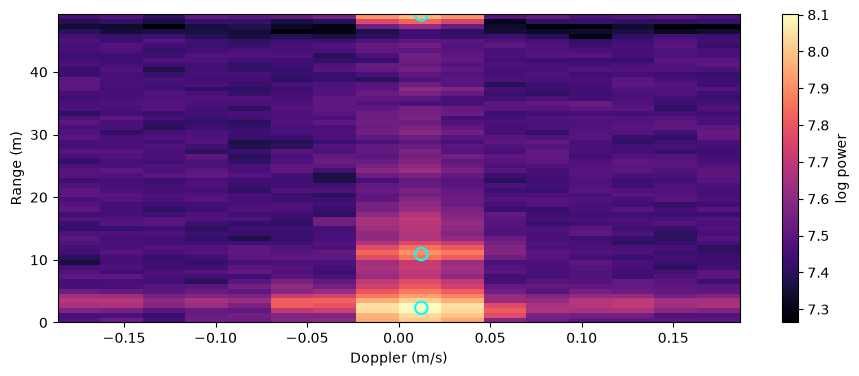

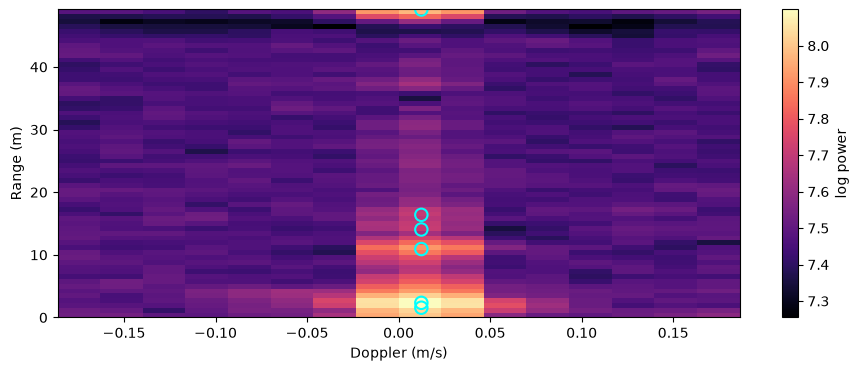

In [71]:
from scipy.ndimage import maximum_filter

rec = train_ds.dataset[4]
play_ds = TLVDataset(rec_dir(rec))
sensor = play_ds.config.sensor()


def preprocess_range_doppler_heatmap(f):
    # get heatmap
    heat = np.asarray(f.output.range_doppler_heatmap, dtype=float)
    # fftshift center at 0m/s, flipud for flipping y-axis
    heat = np.flipud(np.fft.fftshift(heat, axes=1))
    return heat


doppler_bins = sensor.doppler_bins    # m/s, already fftshift-ordered (-max .. +max)
range_bins = sensor.range_bins[::-1]  # m, reversed to match the flipud above

# frame selection
for i, frame in enumerate(play_ds):
    if (i == 25) or (i==60):
        heat = preprocess_range_doppler_heatmap(frame)
        heat = np.log1p(heat)  # minimize the effect of super large values (outliers)

        local_max = (heat == maximum_filter(heat, size=3))
        threshold = heat.mean() + 2 * heat.std()  # two standard deviation above the mean
        peaks = local_max & (heat > threshold)
        range_idx, doppler_idx = np.nonzero(peaks)

        fig, ax = plt.subplots()
        im = ax.imshow(
            heat, aspect="auto", cmap="magma",
            extent=(doppler_bins.min(), doppler_bins.max(), range_bins.min(), range_bins.max()),
        )
        ax.scatter(
            doppler_bins[doppler_idx], range_bins[range_idx],
            s=80, facecolors="none", edgecolors="cyan", linewidths=1.5,
        )
        ax.set_xlabel("Doppler (m/s)")
        ax.set_ylabel("Range (m)")
        plt.colorbar(im, ax=ax, label="log power")
        plt.show()